# Ветви решений задачи о возвращении маятника

В жёлтой работе при $T=4$ получились покой и два зеркальных движения. Теперь время возвращения меняется. Будем искать решения задачи
$$\ddot\theta+\sin\theta=0,\qquad \theta(0)=\theta(T)=0,$$
где конечный угол равен именно нулю. Как и раньше, рассматриваем $|s|\leq1.99$, где $s=\dot\theta(0)$. По очереди проверим, где появляются новые движения, насколько точно можно подобрать $s$ и что происходит, если решать задачу сразу на всей сетке времени.


## Когда появляется новая ветвь

Энергия постоянна:
$$\frac{\dot\theta^2}{2}+1-\cos\theta=\frac{s^2}{2}.$$
При $0<|s|<2$ маятник колеблется, а угол его поворота удовлетворяет $\sin(\theta_{\max}/2)=|s|/2$. Выразим скорость из энергии и проинтегрируем время от нижней точки до поворота. После замены $\sin(\theta/2)=(|s|/2)\sin\varphi$ получаем время между соседними прохождениями нуля:
$$\tau(s)=2\int_0^{\pi/2}\frac{d\varphi}{\sqrt{1-(s^2/4)\sin^2\varphi}}.$$

Ветвь с номером $m$ отвечает $m$ полупериодам, то есть $T=m\tau(s)$. Интеграл растёт с $|s|$ и стремится к $\pi$ при $s\to0$. Поэтому при $T>m\pi$ появляется пара зеркальных движений. Покой существует при всех $T$. На диаграмме ветвь заканчивается, когда $|s|$ достигает границы $1.99$.

Для сравнения посчитаем интеграл квадратурой Гаусса. Численную диаграмму построим независимо: запустим RK4 для сетки положительных $s$ и найдём первые три пересечения нуля после старта. Время пересечения уточним кубической интерполяцией по углу и скорости на концах шага.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import re

plt.rcParams.update({"figure.dpi": 85, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.24})

LIMIT = 1.99
branch_colors = ["#2563eb", "#df7620", "#21855b"]
nodes, weights = np.polynomial.legendre.leggauss(96)
sin2 = np.sin((nodes + 1)*np.pi/4)**2


def half_period(s):
    k = np.asarray(s)[..., None]/2
    return (np.pi/2)*np.sum(weights/np.sqrt(1 - k*k*sin2), axis=-1)


def bisect(f, a, b, tol=2e-12):
    fa, fb = f(a), f(b)
    if fa == 0:
        return a
    if fb == 0:
        return b
    if np.sign(fa) == np.sign(fb):
        raise ValueError("Нужна смена знака на концах интервала.")
    while b-a > tol:
        c = (a+b)/2
        fc = f(c)
        if fc == 0:
            return c
        if np.sign(fc) == np.sign(fa):
            a, fa = c, fc
        else:
            b = c
    return (a+b)/2


def speed_from_period(T, m):
    return bisect(lambda s: m*half_period(s)-T, 0.0, LIMIT)


def rhs(y):
    theta, v = y[:2]
    if len(y) == 2:
        return np.array([v, -np.sin(theta)])
    p, q = y[2:]
    return np.array([v, -np.sin(theta), q, -np.cos(theta)*p])


def rk4(y, h):
    k1 = rhs(y)
    k2 = rhs(y + h*k1/2)
    k3 = rhs(y + h*k2/2)
    k4 = rhs(y + h*k3)
    return y + h*(k1 + 2*k2 + 2*k3 + k4)/6


def shoot(s, T, N, trajectory=False, sensitivity=False):
    s = np.asarray(s, dtype=float)
    zero = np.zeros_like(s)
    parts = [zero, s]
    if sensitivity:
        parts += [zero, np.ones_like(s)]
    y = np.stack(parts)
    h = T/N
    if trajectory:
        angles = [y[0].copy()]
    for _ in range(N):
        y = rk4(y, h)
        if trajectory:
            angles.append(y[0].copy())
    return np.array(angles) if trajectory else y


def crossing_fraction(u0, v0, u1, v1, h):
    def interpolated(z):
        return ((1+2*z)*(1-z)**2*u0 + z*(1-z)**2*h*v0
                + z*z*(3-2*z)*u1 + z*z*(z-1)*h*v1)
    return bisect(interpolated, 0.0, 1.0)


def return_times(s, h=0.01, T_max=11.0):
    y = np.array([np.zeros_like(s), s])
    count = np.zeros(len(s), dtype=int)
    times = np.full((3, len(s)), np.nan)
    for step in range(round(T_max/h)):
        new = rk4(y, h)
        crossed = (y[0] != 0) & (y[0]*new[0] <= 0) & (count < 3)
        for i in np.flatnonzero(crossed):
            fraction = crossing_fraction(*y[:, i], *new[:, i], h)
            times[count[i], i] = (step + fraction)*h
            count[i] += 1
        y = new
    return times


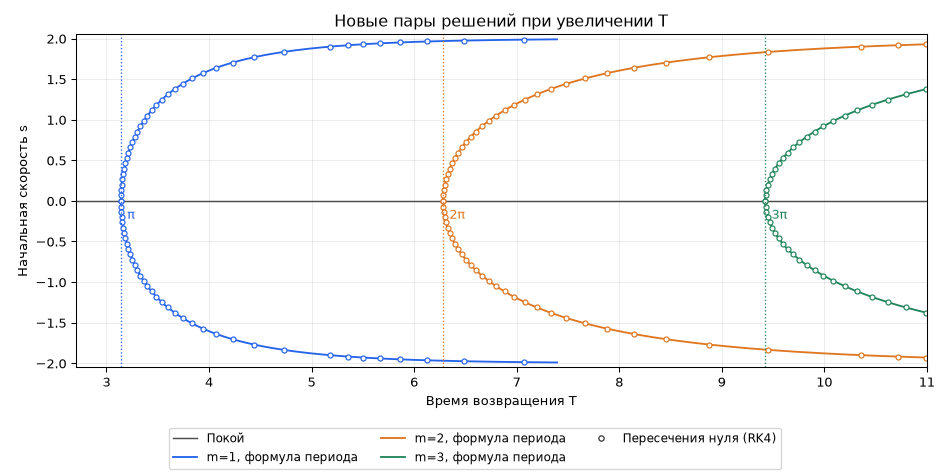

m=1: начало при T=3.141593, граница |s|=1.99 при T=7.393750, max |ΔT| = 3.78e-09
m=2: начало при T=6.283185, граница |s|=1.99 при T=14.787500, max |ΔT| = 5.71e-10
m=3: начало при T=9.424778, граница |s|=1.99 при T=22.181250, max |ΔT| = 7.85e-10


In [2]:
s_grid = np.r_[np.linspace(0.004, 1.9, 88), np.linspace(1.91, LIMIT, 22)]
events = return_times(s_grid)
s_dense = np.linspace(0, LIMIT, 500)

fig, ax = plt.subplots(figsize=(10, 5))
ax.axhline(0, color="0.3", lw=1.1, label="Покой")
for m, color in enumerate(branch_colors, 1):
    for sign in [1, -1]:
        ax.plot(m*half_period(s_dense), sign*s_dense, color=color, lw=1.4,
                label=f"m={m}, формула периода" if sign == 1 else None)
        ax.plot(events[m-1, ::3], sign*s_grid[::3], 'o', color=color,
                ms=3.8, mfc="white", mew=0.9)
    critical = m*np.pi
    ax.axvline(critical, color=color, lw=1, ls=":")
    ax.text(critical+0.06, -0.22, "π" if m == 1 else f"{m}π", color=color)
ax.plot([], [], 'o', color="0.25", mfc="white", ms=4, label="Пересечения нуля (RK4)")
ax.set(xlabel="Время возвращения T", ylabel="Начальная скорость s", xlim=(2.7, 11),
       ylim=(-2.05, 2.05), title="Новые пары решений при увеличении T")
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=9)
fig.tight_layout(rect=[0, 0.11, 1, 1])
plt.show()

for m in range(1, 4):
    errors = np.abs(events[m-1] - m*half_period(s_grid))
    print(f"m={m}: начало при T={m*np.pi:.6f}, граница |s|=1.99 при T={m*half_period(LIMIT):.6f}, "
          f"max |ΔT| = {np.nanmax(errors):.2e}")


## Стрельба и разностная краевая задача

В стрельбе неизвестно одно число $s$. Интегрируем $\theta'=v$, $v'=-\sin\theta$, а затем решаем $R(s)=\theta(T;s)=0$. Для Ньютона нужна производная $R'(s)$. Её можно найти в том же расчёте, если продифференцировать уравнение по $s$:
$$p''+\cos\theta\,p=0,\qquad p(0)=0,\qquad p'(0)=1,\qquad R'(s)=p(T).$$

В разностной задаче неизвестны углы во всех внутренних узлах. При $h=T/N$ уравнения имеют вид
$$F_j=\theta_{j-1}-2\theta_j+\theta_{j+1}+h^2\sin\theta_j=0,\qquad \theta_0=\theta_N=0.$$
На каждом шаге многомерного Ньютона решаем $J\Delta=-F$. У $J$ на главной диагонали стоит $-2+h^2\cos\theta_j$, на соседних диагоналях стоят единицы. Для сравнения со стрельбой восстанавливаем $s$ по трём первым узлам с точностью второго порядка. Решение относим к ветви $m$ по числу смен знака внутри интервала: их должно быть $m-1$.


In [3]:
def shooting_newton(s, T, N, max_steps=35):
    for step in range(max_steps+1):
        y = shoot(s, T, N, sensitivity=True)
        R, derivative = y[0], y[2]
        if abs(R) < 1e-13:
            return s, step, "сходится"
        if step == max_steps:
            break
        if abs(derivative) < 1e-12:
            return s, step, "малая производная"
        next_s = s - R/derivative
        if not np.isfinite(next_s) or abs(next_s) > LIMIT:
            return s, step, "вне интервала"
        s = float(next_s)
    return s, max_steps, "лимит шагов"


def finite_newton(T, N, guess, max_steps=35):
    h = T/N
    u = np.array(guess, dtype=float)
    neighbors = np.diag(np.ones(N-2), 1) + np.diag(np.ones(N-2), -1)
    for step in range(max_steps+1):
        residual = u[:-2] - 2*u[1:-1] + u[2:] + h*h*np.sin(u[1:-1])
        if step == max_steps:
            break
        jacobian = neighbors + np.diag(-2 + h*h*np.cos(u[1:-1]))
        try:
            correction = np.linalg.solve(jacobian, -residual)
        except np.linalg.LinAlgError:
            return u, step, "вырожденный якобиан"
        if not np.all(np.isfinite(correction)) or np.max(np.abs(correction)) > 100:
            return u, step, "большая поправка"
        if np.max(np.abs(correction)) < 3e-10 and np.max(np.abs(residual)) < 1e-13:
            return u, step, "сходится"
        u[1:-1] += correction
    return u, max_steps, "лимит шагов"


def sine_guess(s, T, N, m):
    # У производной стартового профиля в t=0 то же значение s.
    u = s*T/(m*np.pi)*np.sin(m*np.pi*np.arange(N+1)/N)
    u[[0, -1]] = 0
    return u


def initial_speed(u, T):
    return (4*u[1] - u[2])/(2*T/(len(u)-1))


def branch_number(u):
    signs = np.sign(u[1:-1][np.abs(u[1:-1]) > 1e-7])
    if len(signs) == 0:
        return 0
    return int(signs[0])*(1 + np.count_nonzero(signs[1:] != signs[:-1]))


def shooting_root(T, N, left, right, target=0.0):
    return bisect(lambda s: float(shoot(s, T, N)[0]) - target, left, right)


### Сравнение на одних и тех же ветвях

Возьмём $T=4$, $6.4$ и $9.6$. Они дают примеры первой, второй и третьей ветвей. Формулу периода используем как ориентир, чтобы оба метода попали на выбранную ветвь. В стрельбе затем уточняем корень невязки бисекцией, а в разностном методе задаём начальную синусоиду с нужным числом полупериодов. Близость к нужной ветви здесь обеспечена, а зависимость от старта проверим отдельно.

В качестве опорного профиля интегрируем с начальной скоростью из формулы периода на сетке из 2048 интервалов. Во всех сравнениях берём совпадающие узлы времени.


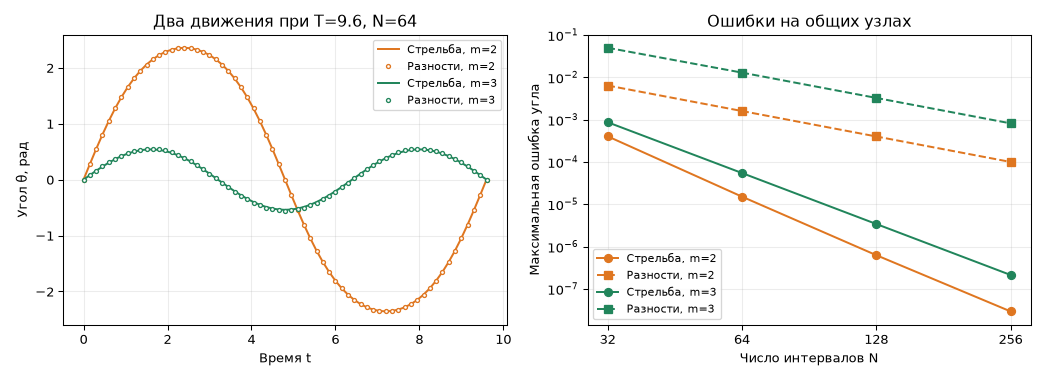

    T  m    N    s (период)   s (стрельба)   s (разности)   e∞ (стр.)  e∞ (разн.)
  4.0  1   32    1.60481303     1.60481225     1.61552210    3.11e-06    1.40e-03
  4.0  1   64    1.60481303     1.60481297     1.60750942    1.93e-07    3.49e-04
  4.0  1  128    1.60481303     1.60481303     1.60548833    1.20e-08    8.73e-05
  4.0  1  256    1.60481303     1.60481303     1.60498193    7.48e-10    2.18e-05
  6.4  1   32    1.97240490     1.97241484     2.00399547    1.56e-05    2.90e-03
  6.4  1   64    1.97240490     1.97240537     1.98052226    9.51e-07    7.22e-04
  6.4  1  128    1.97240490     1.97240493     1.97444816    5.81e-08    1.81e-04
  6.4  1  256    1.97240490     1.97240490     1.97291659    3.59e-09    4.51e-05
  6.4  2   32    0.53423820     0.53407743     0.56459299    1.72e-04    2.29e-02
  6.4  2   64    0.53423820     0.53422795     0.54187484    1.08e-05    5.81e-03
  6.4  2  128    0.53423820     0.53423756     0.53615045    6.76e-07    1.46e-03
  6.4  2  256   

In [4]:
examples = [(4.0, 1), (6.4, 1), (6.4, 2), (9.6, 2), (9.6, 3)]
print(f"{'T':>5} {'m':>2} {'N':>4} {'s (период)':>13} {'s (стрельба)':>14} "
      f"{'s (разности)':>14} {'e∞ (стр.)':>11} {'e∞ (разн.)':>11}")
comparisons = {}
for T, m in examples:
    s_ref = speed_from_period(T, m)
    ref = shoot(s_ref, T, 2048, trajectory=True)
    for N in [32, 64, 128, 256]:
        width = min(0.025, 0.2*s_ref)
        s = shooting_root(T, N, s_ref-width, min(LIMIT, s_ref+width))
        us = shoot(s, T, N, trajectory=True)
        uf, iterations, status = finite_newton(T, N, sine_guess(s_ref, T, N, m))
        assert status == "сходится" and branch_number(uf) == branch_number(us) == m
        truth = ref[::2048//N]
        errors = [np.max(np.abs(us-truth)), np.max(np.abs(uf-truth))]
        comparisons[T, m, N] = errors
        print(f"{T:5.1f} {m:2d} {N:4d} {s_ref:13.8f} {s:14.8f} "
              f"{initial_speed(uf, T):14.8f} {errors[0]:11.2e} {errors[1]:11.2e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for m, color in [(2, branch_colors[1]), (3, branch_colors[2])]:
    T = 9.6
    s_ref = speed_from_period(T, m)
    N = 64
    grid = np.linspace(0, T, N+1)
    s = shooting_root(T, N, s_ref-0.025, s_ref+0.025)
    us = shoot(s, T, N, trajectory=True)
    uf, _, _ = finite_newton(T, N, sine_guess(s_ref, T, N, m))
    axes[0].plot(grid, us, color=color, label=f"Стрельба, m={m}")
    axes[0].plot(grid, uf, "o", ms=3, mfc="white", color=color, label=f"Разности, m={m}")
    ns = np.array([32, 64, 128, 256])
    errors = np.array([comparisons[T, m, n] for n in ns])
    axes[1].loglog(ns, errors[:, 0], "o-", color=color, label=f"Стрельба, m={m}")
    axes[1].loglog(ns, errors[:, 1], "s--", color=color, label=f"Разности, m={m}")
axes[0].set(xlabel="Время t", ylabel="Угол θ, рад", title="Два движения при T=9.6, N=64")
axes[1].set(xlabel="Число интервалов N", ylabel="Максимальная ошибка угла", title="Ошибки на общих узлах")
axes[1].set_xticks(ns, ns)
axes[1].minorticks_off()
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


При сгущении сетки ошибки угла уменьшаются. Например, для третьей ветви при $T=9.6$ удвоение $N$ со 128 до 256 уменьшает ошибку стрельбы примерно в 16 раз, а разностного решения в 4 раза. Это согласуется с четвёртым порядком RK4 и вторым порядком разностей.

Скорость из разностного решения тоже уточняется, но в неё входит ошибка восстановления по первым узлам. На грубой сетке при $T=6.4$, $m=1$ эта оценка даже немного выше 2. Опорная скорость для этой ветви равна $1.9724$, а оценка на мелкой сетке приближается к ней.

## Чувствительность возле начала ветви

Разложение интеграла при малом $s$ даёт $\tau(s)=\pi(1+s^2/16+O(s^4))$. Значит, возле $T_m=m\pi$ скорость на ненулевой ветви растёт как
$$|s|\approx 4\sqrt{\frac{T-T_m}{T_m}}.$$
График здесь крут: даже небольшое изменение времени может заметно сдвинуть найденную скорость.

Можно проверить и чувствительность к конечному углу. Если заменить условие $\theta(T)=0$ на $\theta(T)=\eta$, то при малом $\eta$ поправка к скорости составляет примерно $\eta/R'(s)$. На ветви $\theta(m\tau(s);s)=0$. Дифференцируя это равенство, получаем
$$R'(s)=-\dot\theta(T;s)\,m\tau'(s),\qquad
|R'(s)|\approx 2(T-T_m).$$
Поэтому при приближении к порогу невязка становится пологой и один и тот же допуск по ней означает всё более слабый контроль скорости. Проверим оценку на первой ветви, слегка изменив заданный конечный угол.

У разностного Ньютона та же трудность проявляется в якобиане. Когда модуль одного из его собственных значений мал, поправка может оказаться большой даже при малой невязке. Для сравнения между сетками смотрим на якобиан уравнений $F/h^2$.


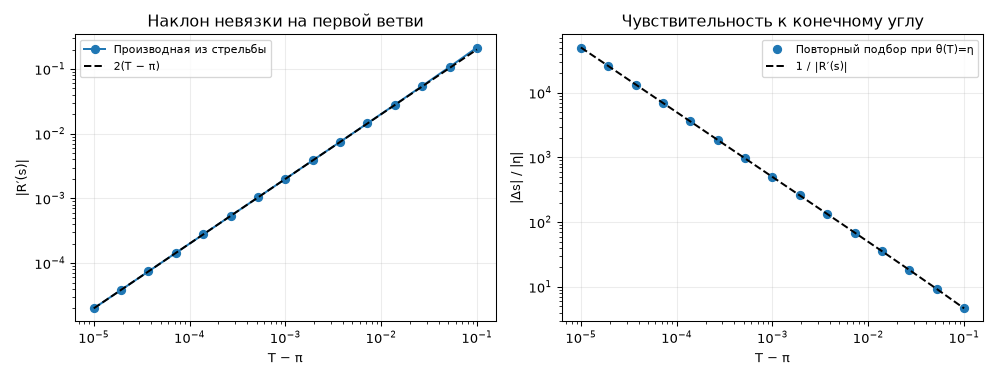

При T−π=1e-05 поправка скорости больше поправки угла примерно в 4.95e+04 раз.


In [5]:
deltas = np.geomspace(1e-5, 0.1, 15)
eta = 1e-9
slopes, measured, predicted = [], [], []
for delta in deltas:
    T = np.pi + delta
    approx = 4*np.sqrt(delta/np.pi)
    s = shooting_root(T, 192, 0.6*approx, 1.4*approx)
    changed = shooting_root(T, 192, 0.6*approx, 1.4*approx, target=eta)
    slope = float(shoot(s, T, 192, sensitivity=True)[2])
    slopes.append(abs(slope))
    measured.append(abs(changed-s)/eta)
    predicted.append(1/abs(slope))

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4))
ax[0].loglog(deltas, slopes, "o-", label="Производная из стрельбы")
ax[0].loglog(deltas, 2*deltas, "k--", label="2(T − π)")
ax[0].set(xlabel="T − π", ylabel="|R′(s)|", title="Наклон невязки на первой ветви")
ax[1].loglog(deltas, measured, "o", label="Повторный подбор при θ(T)=η")
ax[1].loglog(deltas, predicted, "k--", label="1 / |R′(s)|")
ax[1].set(xlabel="T − π", ylabel="|Δs| / |η|", title="Чувствительность к конечному углу")
for a in ax:
    a.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f"При T−π={deltas[0]:g} поправка скорости больше поправки угла примерно в {measured[0]:.2e} раз.")


При $T-\pi=10^{-5}$ изменение конечного угла на $10^{-9}$ рад меняет начальную скорость почти на $5\cdot10^{-5}$. На графике повторный подбор согласуется с наклоном невязки. Чем ближе мы к порогу, тем аккуратнее нужно выбирать допуск.

## Как сетка сдвигает порог

В окрестности покоя заменим $\sin\theta$ на $\theta$. У разностного якобиана на синусоиде с номером $m$ собственное значение равно $h^2-4\sin^2(m\pi/(2N))$. Оно обращается в ноль при
$$T_{m,N}=2N\sin\!\frac{m\pi}{2N}.$$
Этот порог ниже $m\pi$. Поэтому на грубой сетке первая ненулевая ветвь может появиться при $T<\pi$. Это свойство дискретной задачи. Для первой ветви отсутствие ненулевых решений при $T\le T_{1,N}$ следует и из уравнений: умножение на $\theta_j$ и суммирование дают $\sum(\theta_{j+1}-\theta_j)^2=h^2\sum\theta_j\sin\theta_j$. Левая часть не меньше $4\sin^2(\pi/(2N))\sum\theta_j^2$, а правая строго меньше $h^2\sum\theta_j^2$ для ненулевого решения.

В стрельбе порог тоже немного меняется. Для малых углов фаза за один шаг RK4 увеличивается на $\phi(h)=\arg(1-h^2/2+h^4/24+i(h-h^3/6))$. Численный порог находим из $N\phi(T/N)=m\pi$. В таблице сравниваем методы по обе стороны от $\pi$ и проверяем, что происходит при удвоении $N$.


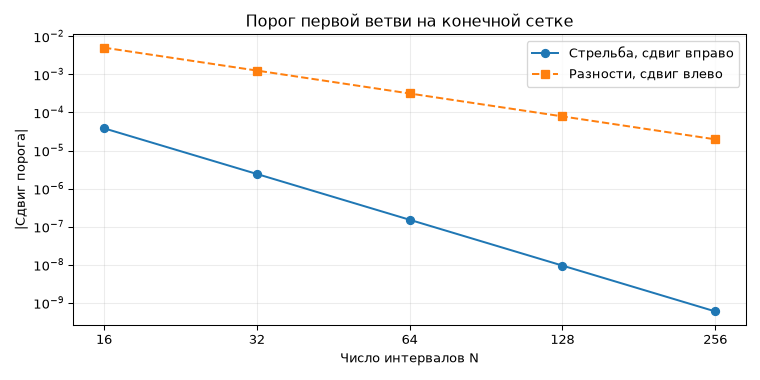

Скорости первой положительной ветви. Прочерк означает, что порог ещё не пройден.
       T−π     N     порог RK4−π     порог МКР−π   s (стрельба)   s (разности)   min |λ(J/h²)|
  -1.0e-04    16       3.838e-05      -5.044e-03              —       0.160806       0.0062829
  -1.0e-04    32       2.424e-06      -1.261e-03              —      0.0771729      0.00147823
  -1.0e-04    64       1.519e-07      -3.154e-04              —      0.0331506     0.000274244
  -1.0e-04   128       9.498e-09      -7.885e-05              —              —               —
  -1.0e-04   256       5.940e-10      -1.971e-05              —              —               —
   1.0e-04    16       3.838e-05      -5.044e-03       0.017715       0.164015      0.00653612
   1.0e-04    32       2.424e-06      -1.261e-03      0.0222917      0.0835474      0.00173252
   1.0e-04    64       1.519e-07      -3.154e-04      0.0225496       0.046033     0.000528803
   1.0e-04   128       9.498e-09      -7.885e-05      0.0225657 

In [6]:
def finite_threshold(N, m=1):
    return 2*N*np.sin(m*np.pi/(2*N))


def shooting_threshold(N, m=1):
    def angle_error(T):
        h = T/N
        phase = np.arctan2(h-h**3/6, 1-h*h/2+h**4/24)
        return N*phase-m*np.pi
    return bisect(angle_error, m*np.pi-0.01, m*np.pi+0.05)


mesh_sizes = [16, 32, 64, 128, 256]
onsets = np.array([[shooting_threshold(N), finite_threshold(N)] for N in mesh_sizes])
print("Скорости первой положительной ветви. Прочерк означает, что порог ещё не пройден.")
print(f"{'T−π':>10} {'N':>5} {'порог RK4−π':>15} {'порог МКР−π':>15} "
      f"{'s (стрельба)':>14} {'s (разности)':>14} {'min |λ(J/h²)|':>15}")
threshold_trials = {}
for delta in [-1e-4, 1e-4]:
    T = np.pi + delta
    for N, (crit_s, crit_f) in zip(mesh_sizes, onsets):
        s_s = None
        s_f = None
        gap = None
        if T > crit_s:
            s_s = shooting_root(T, N, 1e-5, 0.2)
        if T > crit_f:
            guess = 4*np.sqrt((T-crit_f)/crit_f)
            u, _, status = finite_newton(T, N, sine_guess(guess, T, N, 1))
            assert status == "сходится" and branch_number(u) == 1
            s_f = initial_speed(u, T)
            h = T/N
            J = (np.diag(-2+h*h*np.cos(u[1:-1]))
                 + np.diag(np.ones(N-2), 1) + np.diag(np.ones(N-2), -1))/h**2
            gap = np.min(np.abs(np.linalg.eigvalsh(J)))
        threshold_trials[delta, N] = (s_s, s_f, gap)
        fields = ["—" if v is None else f"{v:.6g}" for v in [s_s, s_f, gap]]
        print(f"{delta:10.1e} {N:5d} {crit_s-np.pi:15.3e} {crit_f-np.pi:15.3e} "
              f"{fields[0]:>14} {fields[1]:>14} {fields[2]:>15}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.loglog(mesh_sizes, onsets[:, 0]-np.pi, "o-", label="Стрельба, сдвиг вправо")
ax.loglog(mesh_sizes, np.pi-onsets[:, 1], "s--", label="Разности, сдвиг влево")
ax.set(xlabel="Число интервалов N", ylabel="|Сдвиг порога|", title="Порог первой ветви на конечной сетке")
ax.set_xticks(mesh_sizes, mesh_sizes)
ax.minorticks_off()
ax.legend()
fig.tight_layout()
plt.show()


При $T=\pi-10^{-4}$ ненулевая ветвь видна в разностном расчёте при $N=16$, $32$ и $64$. При $N=128$ её уже нет: разностный порог становится выше выбранного $T$. В стрельбе сдвиг первого порога примерно в 16 раз уменьшается при удвоении $N$, а в разностном методе примерно в 4 раза.

Теперь возьмём времена на $10^{-4}$ выше $2\pi$ и $3\pi$. Ниже проверяем только новые ветви, с двумя и тремя полупериодами. Более ранние ветви при этих временах могут уже существовать.

In [7]:

print(f"{'m':>2} {'N':>4} {'порог RK4−mπ':>15} {'порог МКР−mπ':>15} "
      f"{'s (период)':>12} {'s (стрельба)':>14} {'s (разности)':>14}")
higher_trials = {}
for m in [2, 3]:
    T = m*np.pi + 1e-4
    s_ref = speed_from_period(T, m)
    for N in [32, 128, 256]:
        crit_s = shooting_threshold(N, m)
        crit_f = finite_threshold(N, m)
        s = shooting_root(T, N, 1e-5, 0.1) if T > crit_s else None
        guess = 4*np.sqrt((T-crit_f)/crit_f)
        u, _, status = finite_newton(T, N, sine_guess(guess, T, N, m))
        assert status == "сходится" and branch_number(u) == m
        check_s = initial_speed(u, T)
        higher_trials[m, N] = (s, check_s, s_ref)
        shoot_field = "—" if s is None else f"{s:.8f}"
        print(f"{m:2d} {N:4d} {crit_s-m*np.pi:15.3e} {crit_f-m*np.pi:15.3e} "
              f"{s_ref:12.8f} {shoot_field:>14} {check_s:14.8f}")


 m    N    порог RK4−mπ    порог МКР−mπ   s (период)   s (стрельба)   s (разности)
 2   32       7.676e-05      -1.009e-02   0.01595741     0.00769285     0.16321842
 2  128       3.037e-07      -6.308e-04   0.01595741     0.01593315     0.04317457
 2  256       1.900e-08      -1.577e-04   0.01595741     0.01595589     0.02562211
 3   32       5.730e-04      -3.403e-02   0.01302924              —     0.24784125
 3  128       2.304e-06      -2.129e-03   0.01302924     0.01287828     0.06162874
 3  256       1.442e-07      -5.322e-04   0.01302924     0.01301985     0.03277696


При $N=32$ стрельба занижает скорость второй ветви, а третья ещё не появилась на этой сетке. При $N=128$ обе ветви есть. Разностный метод на грубой сетке даёт завышенные скорости. Чем больше номер ветви, тем больше полупериодов нужно уложить в то же число шагов и тем сильнее сдвиг порога.

## Что меняет начальное приближение

Возьмём время чуть выше $\pi$, когда покой и два колебательных решения близки. Для стрельбы перебираем начальную скорость. Для разностного Ньютона стартуем с синусоиды, производная которой в нуле равна той же скорости. Каждый метод может сделать до 35 шагов. Серым обозначаем покой, цветом — знак найденного движения. Крестик означает остановку алгоритма до сходимости. Отсутствие сходимости из конкретного старта не говорит об отсутствии решения.

Сравним две временные сетки. Они имеют разные пороги и разные начальные скорости ненулевых решений, поэтому карта показывает результат одновременно двух факторов: дискретизации и выбора начального приближения.


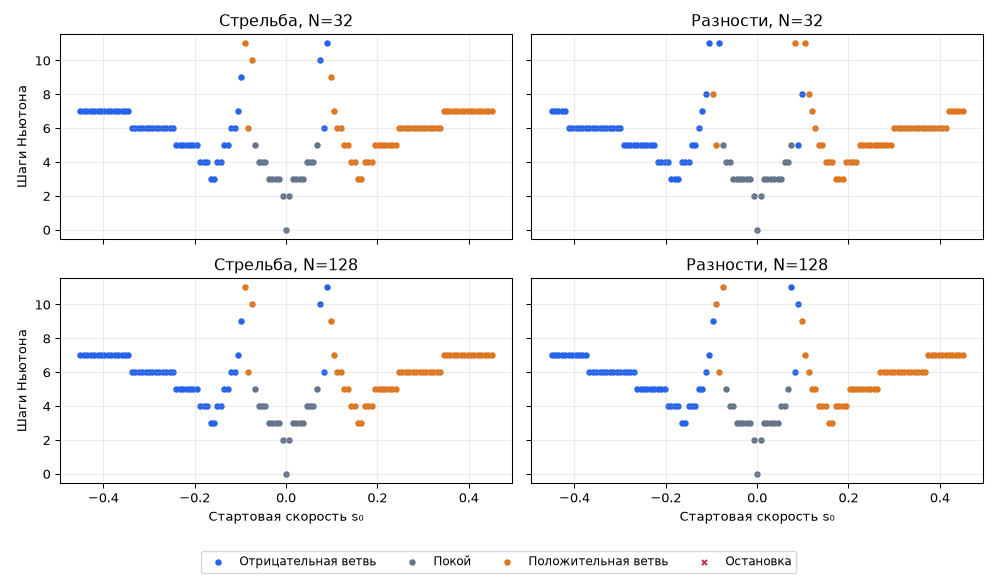

Стрельба, N=32: отрицательная ветвь — 51, покой — 19, положительная ветвь — 51, остановка — 0
Разности, N=32: отрицательная ветвь — 50, покой — 21, положительная ветвь — 50, остановка — 0
Стрельба, N=128: отрицательная ветвь — 51, покой — 19, положительная ветвь — 51, остановка — 0
Разности, N=128: отрицательная ветвь — 51, покой — 19, положительная ветвь — 51, остановка — 0

Старты, для которых результат разностного Ньютона меняется при сгущении:
s₀=-0.0975: положительная ветвь → отрицательная ветвь
s₀=-0.0825: отрицательная ветвь → положительная ветвь
s₀=-0.0750: покой → положительная ветвь
s₀=+0.0750: покой → отрицательная ветвь
s₀=+0.0825: положительная ветвь → отрицательная ветвь
s₀=+0.0975: отрицательная ветвь → положительная ветвь
Старт в экстремуме невязки, s₀≈0.09204028: малая производная.


In [8]:
T_start = np.pi + 0.005
starts = np.linspace(-0.45, 0.45, 121)
starts[len(starts)//2] = 0
outcomes = {}
for N in [32, 128]:
    for name in ["Стрельба", "Разности"]:
        category = []
        steps = []
        for s0 in starts:
            if name == "Стрельба":
                s, count, status = shooting_newton(float(s0), T_start, N)
                if status == "сходится":
                    value = int(np.sign(s)) if abs(s) > 1e-7 else 0
            else:
                u, count, status = finite_newton(T_start, N, sine_guess(s0, T_start, N, 1))
                if status == "сходится":
                    value = branch_number(u)
            category.append(value if status == "сходится" else 2)
            steps.append(count)
        outcomes[name, N] = (np.array(category), np.array(steps))

labels = {-1:"Отрицательная ветвь", 0:"Покой", 1:"Положительная ветвь", 2:"Остановка"}
colors = {-1:"#2563eb", 0:"#64748b", 1:"#df7620", 2:"#be344a"}
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.1), sharex=True, sharey=True)
for ax, ((name, N), (category, steps)) in zip(axes.flat, outcomes.items()):
    assert np.all(np.isin(category, list(labels)))
    for key, label in labels.items():
        pick = category == key
        ax.scatter(starts[pick], steps[pick], s=15, color=colors[key],
                   marker="x" if key == 2 else "o", label=label)
    ax.set_title(f"{name}, N={N}")
    if ax in axes[:, 0]:
        ax.set_ylabel("Шаги Ньютона")
    if ax in axes[-1, :]:
        ax.set_xlabel("Стартовая скорость s₀")
    print(f"{name}, N={N}: " + ", ".join(f"{label.lower()} — {np.sum(category==k)}"
                                         for k, label in labels.items()))
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=9)
fig.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()


print("\nСтарты, для которых результат разностного Ньютона меняется при сгущении:")
coarse = outcomes["Разности", 32][0]
fine = outcomes["Разности", 128][0]
for i in np.flatnonzero(coarse != fine):
    print(f"s₀={starts[i]:+.4f}: {labels[coarse[i]].lower()} → {labels[fine[i]].lower()}")

flat = bisect(lambda z: float(shoot(z, T_start, 128, sensitivity=True)[2]), 0.02, 0.15)
_, _, status = shooting_newton(flat, T_start, 128)
print(f"Старт в экстремуме невязки, s₀≈{flat:.8f}: {status}.")


На равномерной сетке стартов оба метода сходятся. Возле покоя встречаются старты, для которых знак найденного движения противоположен знаку стартовой скорости. При сгущении разностной сетки часть точек меняет цвет. Есть и более чувствительные старты между узлами карты: в экстремуме невязки её производная почти нулевая, и стрельба останавливается. Начальное приближение важно даже при наличии устойчиво вычисляемой ветви.

## Как выглядят движения после появления второй ветви

При $T=2\pi+0.3$ существуют пять решений в выбранном диапазоне скоростей. Слева направо показаны две отрицательные скорости, покой и две положительные скорости. На графике видно, что два маятника успевают сделать один полупериод, два других — по два полупериода. Все пять заканчивают в нижнем положении.


In [9]:
T_anim = 2*np.pi + 0.3
positive = [speed_from_period(T_anim, m) for m in [1, 2]]
speeds = np.array([-positive[0], -positive[1], 0, positive[1], positive[0]])
N_anim = 512
times = np.linspace(0, T_anim, N_anim+1)
angles = shoot(speeds, T_anim, N_anim, trajectory=True)
frame_indices = np.arange(0, N_anim+1, 8)
colors = ["#2563eb", "#0891b2", "#64748b", "#9a52ba", "#df7620"]
fig = plt.figure(figsize=(10.5, 5))
layout = fig.add_gridspec(2, 5, height_ratios=[1, 1.25])
rods = []
for j, (speed, color) in enumerate(zip(speeds, colors)):
    ax = fig.add_subplot(layout[0, j])
    ax.set(xlim=(-1.14, 1.14), ylim=(-1.14, 1.1), aspect="equal",
           title=f"s = {speed:.3f}", xticks=[], yticks=[])
    ax.axvline(0, lw=0.7, ls=":", color="0.65")
    rod, = ax.plot([0, 0], [0, -1], "o-", lw=2, ms=6, color=color)
    rods.append(rod)
ax = fig.add_subplot(layout[1, :])
for j, color in enumerate(colors):
    ax.plot(times, angles[:, j], color=color)
cursor = ax.axvline(0, color="0.3", ls="--", lw=1)
dots = ax.scatter(np.zeros(5), angles[0], c=colors, s=24, zorder=4)
ax.set(xlabel="Время t", ylabel="Угол θ, рад", xlim=(0, T_anim))
title = fig.suptitle("t = 0.00")
fig.tight_layout(rect=[0, 0, 1, 0.93])


def update(frame):
    i = frame_indices[frame]
    for j, rod in enumerate(rods):
        theta = angles[i, j]
        rod.set_data([0, np.sin(theta)], [0, -np.cos(theta)])
    t = times[i]
    cursor.set_xdata([t, t])
    dots.set_offsets(np.column_stack((np.full(5, t), angles[i])))
    title.set_text(f"t = {t:.2f} из {T_anim:.2f}")


animation = FuncAnimation(fig, update, frames=len(frame_indices), interval=65, repeat=False)
plt.close(fig)
html = animation.to_jshtml(default_mode="once")
html = re.sub(r'<link\b[^>]*font-awesome[^>]*>', '', html)
icons = {"fa fa-minus": "−", "fa fa-plus": "+", "fa fa-play": "▶", "fa fa-pause": "⏸",
         "fa fa-fast-backward": "⏮", "fa fa-step-backward": "⏪",
         "fa fa-play fa-flip-horizontal": "◀", "fa fa-step-forward": "⏩", "fa fa-fast-forward": "⏭"}
for name, symbol in icons.items():
    html = html.replace(f'<i class="{name}"></i>', f'<span>{symbol}</span>')
display(HTML(html))


<HTML animation>

## Вывод

Новое движение становится возможным, как только заданного времени хватает ещё на один полупериод малых колебаний. У маятника период растёт с амплитудой, поэтому чуть выше $m\pi$ находится пара движений с малой амплитудой. Дальше начальные скорости этой пары расходятся.

Вдали от порогов оба численных метода дают одни и те же ветви при сгущении сетки. Вблизи порога полезно сравнить сам сдвиг порога с расстоянием до $m\pi$. Иначе можно получить решение разностной задачи там, где непрерывная задача допускает только покой. Даже при достаточно мелкой сетке выбор начального приближения остаётся существенным: рядом существуют три решения, а наклон невязки и модуль одного собственного значения якобиана становятся малы.
